In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import carregar_noaa_por_tipo, carregar_bacias, pareados_por_raio, tabela_ajustes, plotar_varredura, plotar_mosaico

tipos = carregar_noaa_por_tipo()
bacias = carregar_bacias(tipos)
print({nome: len(df) for nome, df in tipos.items()}, "| bacias:", len(bacias))

{'Água oceânica': 14363, 'Areia de praia': 893, 'Sedimento oceânico': 319, 'Nurdle Patrol': 10615} | bacias: 182044


In [2]:
pareados = pareados_por_raio(bacias, tipos, raios=range(1, 23))
tab = tabela_ajustes(pareados)
print(tab[tab["R_km"].isin([5, 22])].round(3).to_string(index=False))

          Conjunto  R_km  Pop_min                X    N   beta    se  r2_pct  p_value    rho  r2_bins_pct  beta_bins_w
     Água oceânica     5        0 total_population  754  0.346 0.032  13.246    0.000  0.418       96.382        0.344
     Água oceânica     5        0         area_km2  754  0.575 0.092   4.970    0.000  0.315       42.263        0.553
    Areia de praia     5        0 total_population  333  0.201 0.057   3.605    0.000  0.205       35.561        0.187
    Areia de praia     5        0         area_km2  333  0.170 0.103   0.821    0.099  0.141       31.989        0.221
Sedimento oceânico     5        0 total_population   84  0.265 0.083  11.168    0.002  0.366       92.283        0.296
Sedimento oceânico     5        0         area_km2   84  0.290 0.174   3.293    0.099  0.276       47.242        0.361
     Nurdle Patrol     5        0 total_population 1319 -0.073 0.018   1.286    0.000 -0.102       23.279       -0.076
     Nurdle Patrol     5        0         area_k

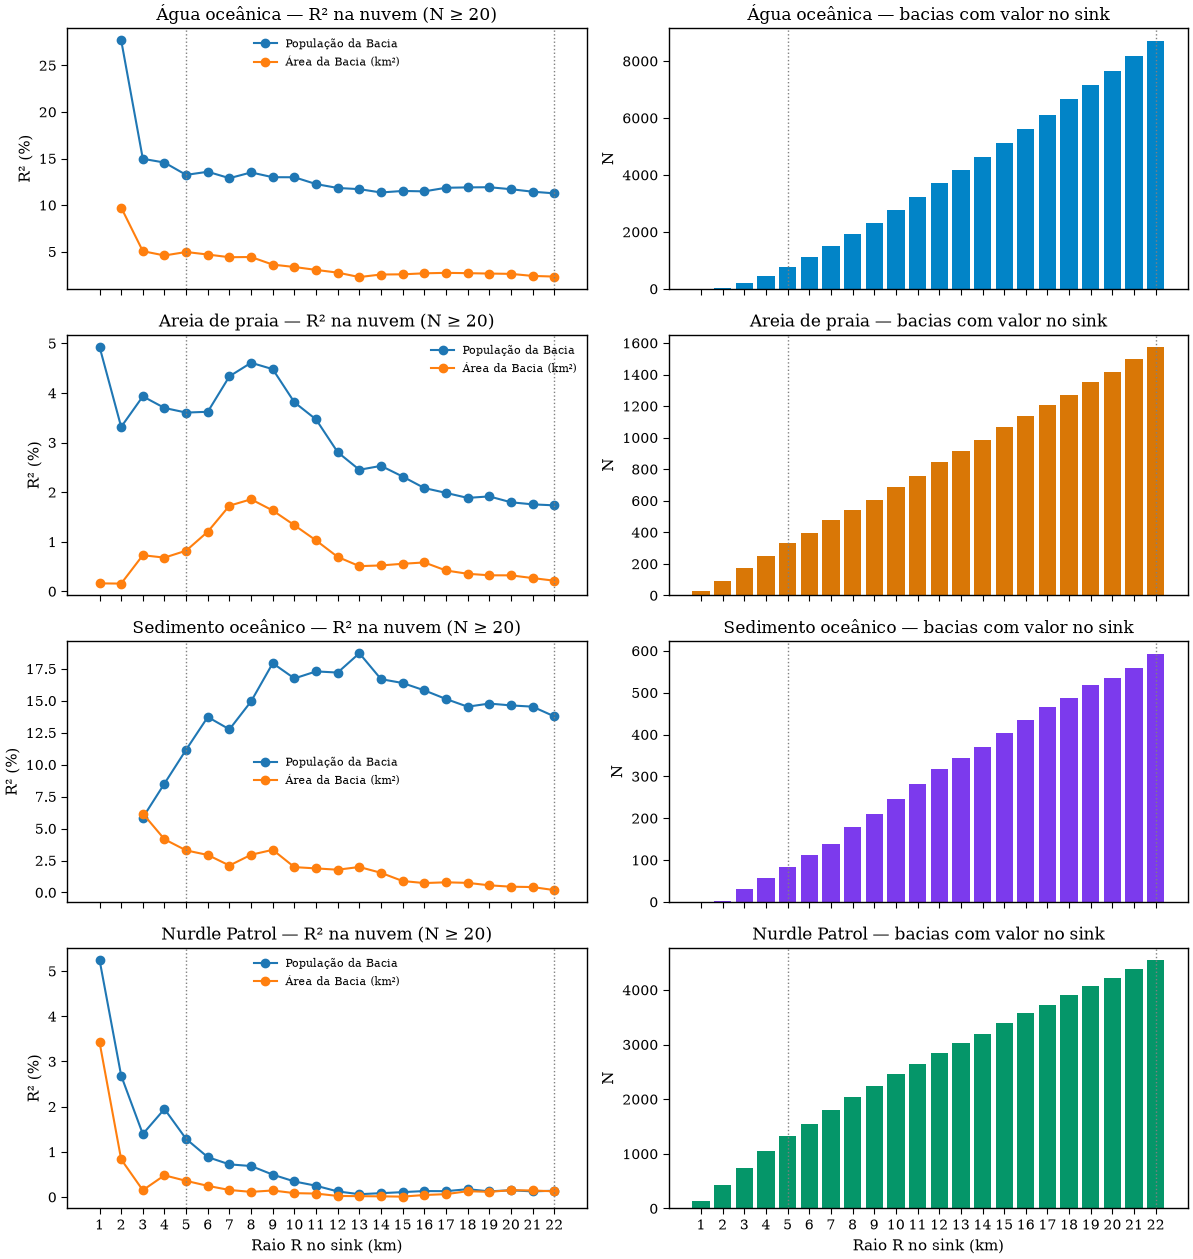

In [3]:
plotar_varredura(tab)

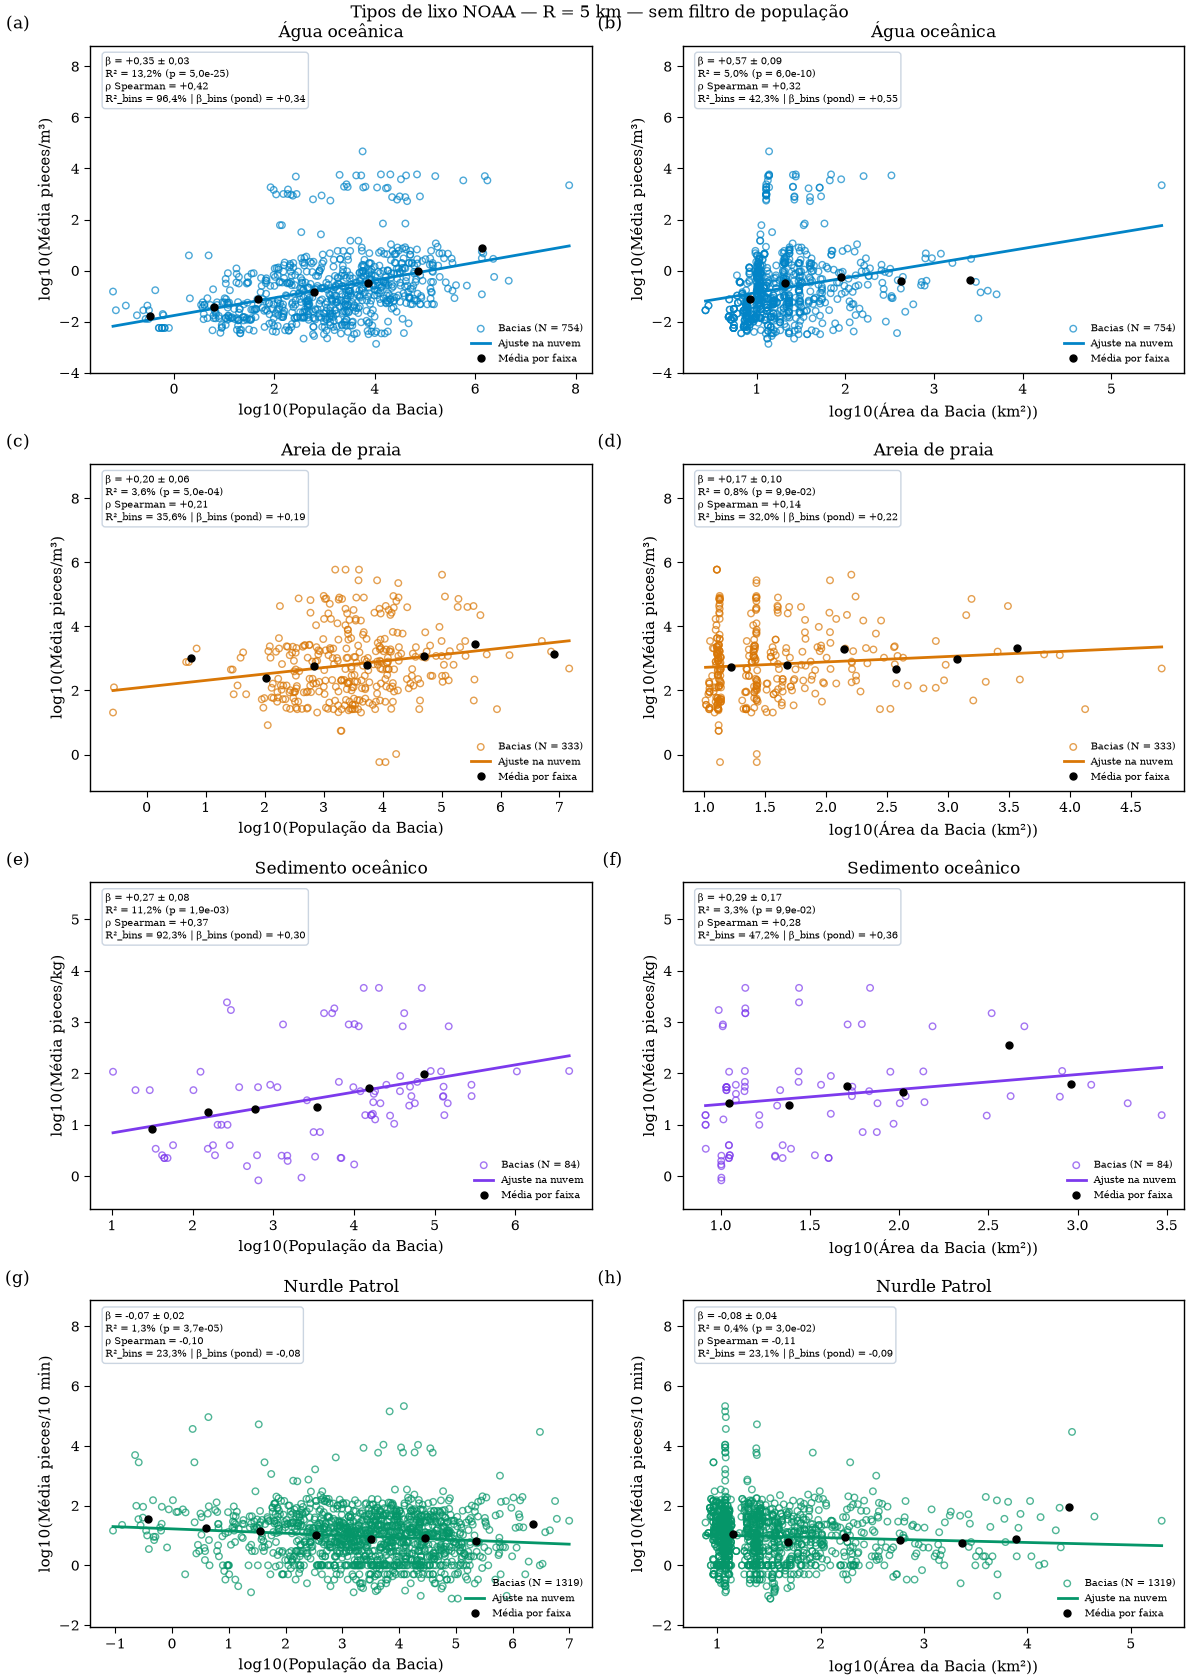

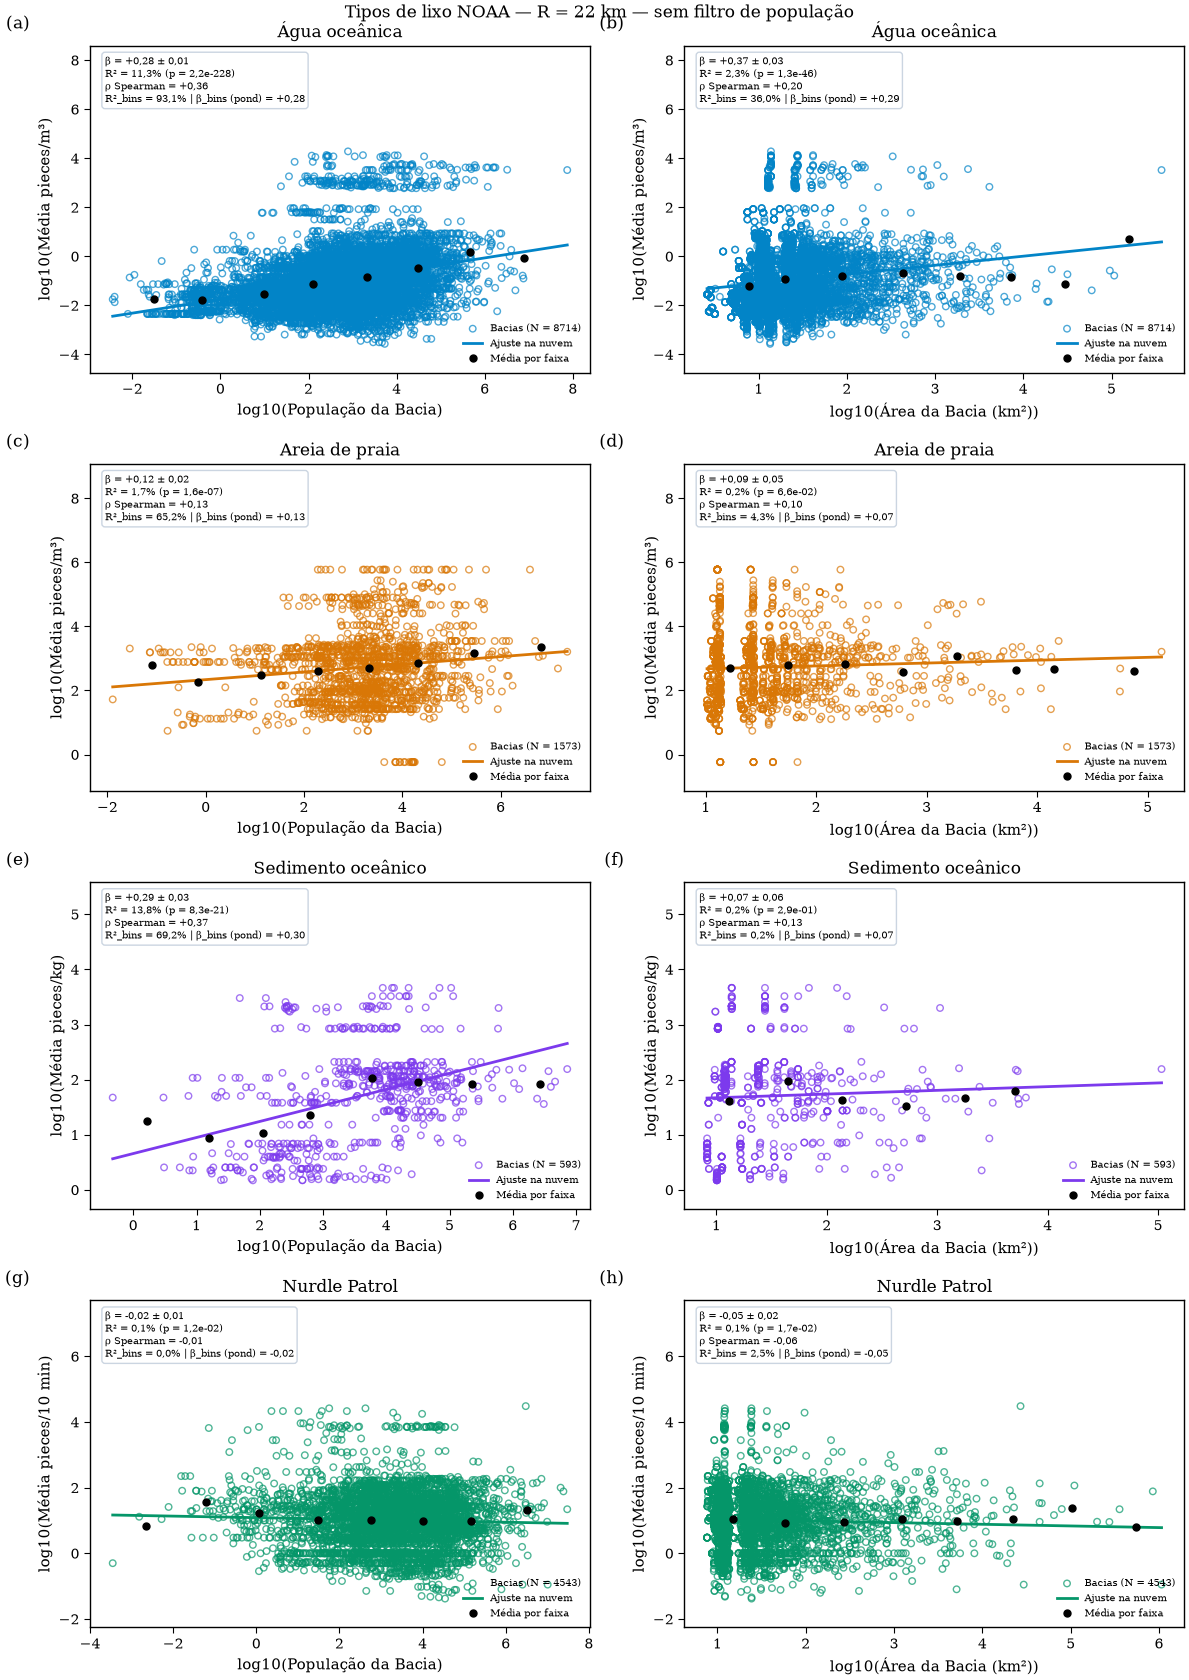

In [4]:
for r in (5, 22):
    plotar_mosaico(pareados[r], f"Tipos de lixo NOAA — R = {r} km")